<h2>Célula 1 — Importações e caminhos

In [1]:

from pathlib import Path
import pandas as pd

# Pasta onde o Jupyter está executando
PASTA_DATASETS = Path.cwd()

# Caminhos dos arquivos
CAMINHO_PAYSIM = PASTA_DATASETS / "PaySim.csv"
CAMINHO_CREDITCARD = PASTA_DATASETS / "CreditCard.csv"

print("Pasta atual:", PASTA_DATASETS)

for caminho in [CAMINHO_PAYSIM, CAMINHO_CREDITCARD]:
    if caminho.is_file():
        tamanho_gb = caminho.stat().st_size / (1024 ** 3)
        print(f"{caminho.name}: {tamanho_gb:.2f} GiB")
    else:
        print(f"Arquivo não encontrado: {caminho}")


Pasta atual: c:\Users\Caio\Desktop\Datasets
PaySim.csv: 0.46 GiB
CreditCard.csv: 0.14 GiB


<h2>Célula 2 — Verificar a estrutura da PaySim

In [2]:

# Ler apenas os 10 primeiros registros
amostra_paysim = pd.read_csv(
    CAMINHO_PAYSIM,
    nrows=10
)

print("Colunas encontradas:")
print(amostra_paysim.columns.tolist())

print("\nTipos de dados:")
print(amostra_paysim.dtypes)

print("\nPrimeiros cinco registros:")
display(amostra_paysim.head())


Colunas encontradas:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Tipos de dados:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Primeiros cinco registros:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


<h2>Célula 3 — Verificar a estrutura da CreditCard

In [3]:

# Ler apenas os 10 primeiros registros
amostra_creditcard = pd.read_csv(
    CAMINHO_CREDITCARD,
    nrows=10
)

print("Colunas encontradas:")
print(amostra_creditcard.columns.tolist())

print("\nTipos de dados:")
print(amostra_creditcard.dtypes)

print("\nPrimeiros cinco registros:")
display(amostra_creditcard.head())


Colunas encontradas:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Tipos de dados:
Time        int64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Primeiros cinco registros:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<h2>Célula 4 - Carregar a PaySim completa

In [4]:

# Carregar toda a base PaySim
df_paysim = pd.read_csv(CAMINHO_PAYSIM)

print("Base PaySim carregada com sucesso!")

print("\nDimensões:")
print(df_paysim.shape)

print("\nMemória utilizada pelo DataFrame:")
memoria_mb = (
    df_paysim.memory_usage(deep=True).sum() / 1024**2
)
print(f"{memoria_mb:.2f} MiB")

print("\nInformações gerais:")
df_paysim.info()


Base PaySim carregada com sucesso!

Dimensões:
(6362620, 11)

Memória utilizada pelo DataFrame:
1452.57 MiB

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


<h2>Célula 5 — Qualidade e distribuição dos dados

In [5]:

# Valores ausentes
print("=== VALORES AUSENTES ===")
tabela_ausentes = pd.DataFrame({
    "Quantidade": df_paysim.isna().sum(),
    "Percentual (%)": df_paysim.isna().mean() * 100
})
display(tabela_ausentes)

# Distribuição das classes
print("\n=== DISTRIBUIÇÃO DAS CLASSES ===")
tabela_classes = (
    df_paysim["isFraud"]
    .value_counts()
    .sort_index()
    .rename_axis("isFraud")
    .reset_index(name="Quantidade")
)
tabela_classes["Percentual (%)"] = (
    tabela_classes["Quantidade"] / len(df_paysim) * 100
)
display(tabela_classes)

# Tipos de transação
print("\n=== TIPOS DE TRANSAÇÃO ===")
tabela_tipos = (
    df_paysim["type"]
    .value_counts()
    .rename_axis("Tipo")
    .reset_index(name="Quantidade")
)
tabela_tipos["Percentual (%)"] = (
    tabela_tipos["Quantidade"] / len(df_paysim) * 100
)
display(tabela_tipos)

# Indicador de sinalização de fraude
print("\n=== isFlaggedFraud ===")
display(df_paysim["isFlaggedFraud"].value_counts().sort_index())

# Intervalo temporal
print("\n=== INTERVALO TEMPORAL ===")
print("Step mínimo:", df_paysim["step"].min())
print("Step máximo:", df_paysim["step"].max())


=== VALORES AUSENTES ===


,Quantidade,Percentual (%)
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0



=== DISTRIBUIÇÃO DAS CLASSES ===


,isFraud,Quantidade,Percentual (%)
0,0,6354407,99.870918
1,1,8213,0.129082



=== TIPOS DE TRANSAÇÃO ===


,Tipo,Quantidade,Percentual (%)
0,CASH_OUT,2237500,35.166331
1,PAYMENT,2151495,33.814608
2,CASH_IN,1399284,21.992261
3,TRANSFER,532909,8.375622
4,DEBIT,41432,0.651178



=== isFlaggedFraud ===


isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


=== INTERVALO TEMPORAL ===
Step mínimo: 1
Step máximo: 743


<h2>Célula 6 — Verificar duplicatas

In [6]:

print("=== DUPLICATAS ===")

# Registros completamente idênticos
duplicatas = df_paysim.duplicated().sum()

print(f"Registros duplicados: {duplicatas:,}")
print(
    f"Percentual de duplicatas: "
    f"{duplicatas / len(df_paysim) * 100:.4f}%"
)


=== DUPLICATAS ===
Registros duplicados: 0
Percentual de duplicatas: 0.0000%


<h2>Célula 7 — Fraudes por tipo de transação

In [7]:

print("=== FRAUDES POR TIPO DE TRANSAÇÃO ===")

# Cruzar o tipo de transação com a classe
tabela_tipo_fraude = pd.crosstab(
    df_paysim["type"],
    df_paysim["isFraud"]
)

# Garantir a presença das duas colunas
tabela_tipo_fraude = tabela_tipo_fraude.reindex(
    columns=[0, 1],
    fill_value=0
)

tabela_tipo_fraude.columns = [
    "Legítimas",
    "Fraudes"
]

# Calcular total e taxa de fraude por tipo
tabela_tipo_fraude["Total"] = (
    tabela_tipo_fraude["Legítimas"] +
    tabela_tipo_fraude["Fraudes"]
)

tabela_tipo_fraude["Taxa de fraude (%)"] = (
    tabela_tipo_fraude["Fraudes"] /
    tabela_tipo_fraude["Total"] * 100
)

# Ordenar pela quantidade de fraudes
tabela_tipo_fraude = tabela_tipo_fraude.sort_values(
    "Fraudes",
    ascending=False
)

display(tabela_tipo_fraude)


=== FRAUDES POR TIPO DE TRANSAÇÃO ===


,Legítimas,Fraudes,Total,Taxa de fraude (%)
type,,,,
CASH_OUT,2233384,4116,2237500,0.183955
TRANSFER,528812,4097,532909,0.768799
CASH_IN,1399284,0,1399284,0.000000
DEBIT,41432,0,41432,0.000000
PAYMENT,2151495,0,2151495,0.000000


<h2>Célula 8 — Relação entre isFlaggedFraud e isFraud

In [8]:

print("=== isFlaggedFraud x isFraud ===")

tabela_sinalizacao = pd.crosstab(
    df_paysim["isFlaggedFraud"],
    df_paysim["isFraud"],
    rownames=["Sinalização"],
    colnames=["Fraude real"]
)

display(tabela_sinalizacao)

print("\n=== FRAUDES SINALIZADAS ===")

fraudes_sinalizadas = (
    (df_paysim["isFlaggedFraud"] == 1) &
    (df_paysim["isFraud"] == 1)
).sum()

total_fraudes = df_paysim["isFraud"].sum()

percentual_detectado = (
    fraudes_sinalizadas / total_fraudes * 100
)

print(f"Fraudes sinalizadas: {fraudes_sinalizadas:,}")
print(f"Total de fraudes: {total_fraudes:,}")
print(
    f"Percentual de fraudes sinalizadas: "
    f"{percentual_detectado:.4f}%"
)


=== isFlaggedFraud x isFraud ===


Fraude real,0,1
Sinalização,,
0,6354407,8197
1,0,16



=== FRAUDES SINALIZADAS ===
Fraudes sinalizadas: 16
Total de fraudes: 8,213
Percentual de fraudes sinalizadas: 0.1948%


<h2>Célula 9 — Fraudes ao longo do tempo

=== DISTRIBUIÇÃO TEMPORAL ===
Quantidade de steps: 743
Steps com pelo menos uma fraude: 741
Steps sem fraudes: 2

Primeiros registros:


,step,Total,Fraudes,Taxa de fraude (%)
0,1,2708,16,0.590842
1,2,1014,8,0.788955
2,3,552,4,0.724638
3,4,565,10,1.769912
4,5,665,6,0.902256



Últimos registros:


,step,Total,Fraudes,Taxa de fraude (%)
738,739,10,10,100.0
739,740,6,6,100.0
740,741,22,22,100.0
741,742,14,14,100.0
742,743,8,8,100.0


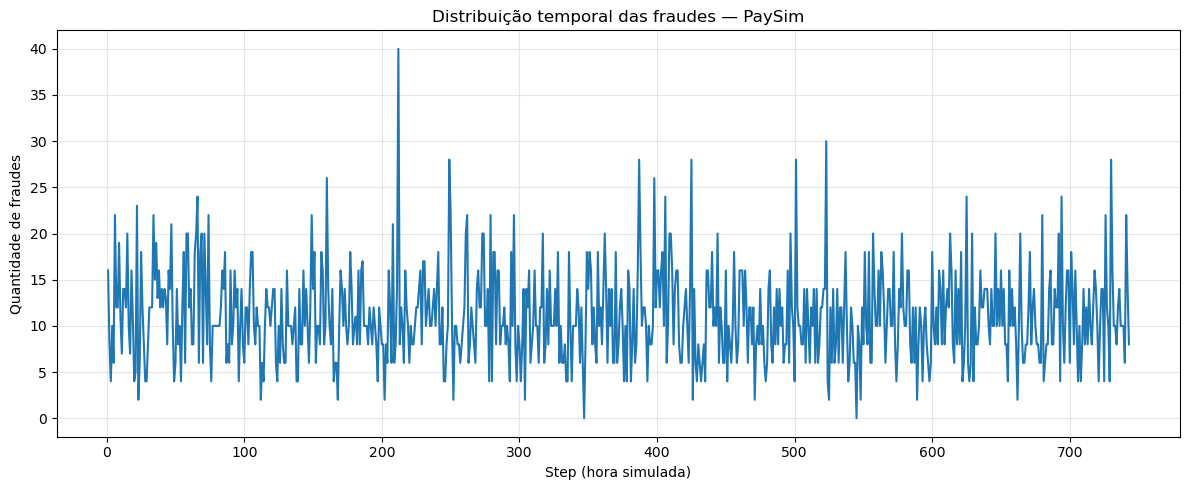

In [9]:

import matplotlib.pyplot as plt

# Agrupar as transações por step
tabela_temporal = (
    df_paysim.groupby("step")["isFraud"]
    .agg(
        Total="count",
        Fraudes="sum"
    )
    .reset_index()
)

# Calcular taxa de fraude por step
tabela_temporal["Taxa de fraude (%)"] = (
    tabela_temporal["Fraudes"] /
    tabela_temporal["Total"] * 100
)

print("=== DISTRIBUIÇÃO TEMPORAL ===")
print("Quantidade de steps:", len(tabela_temporal))

print(
    "Steps com pelo menos uma fraude:",
    (tabela_temporal["Fraudes"] > 0).sum()
)

print(
    "Steps sem fraudes:",
    (tabela_temporal["Fraudes"] == 0).sum()
)

print("\nPrimeiros registros:")
display(tabela_temporal.head())

print("\nÚltimos registros:")
display(tabela_temporal.tail())

# Gráfico da quantidade de fraudes
plt.figure(figsize=(12, 5))

plt.plot(
    tabela_temporal["step"],
    tabela_temporal["Fraudes"]
)

plt.title("Distribuição temporal das fraudes — PaySim")
plt.xlabel("Step (hora simulada)")
plt.ylabel("Quantidade de fraudes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<h2>Célula 10 — Avaliar possíveis divisões temporais

In [10]:

print("=== SIMULAÇÃO DE DIVISÕES TEMPORAIS ===")

for proporcao_treino in [0.70, 0.80]:
    limite_step = df_paysim["step"].quantile(
        proporcao_treino
    )

    treino = df_paysim["step"] <= limite_step
    teste = df_paysim["step"] > limite_step

    print(
        f"\nDivisão aproximada "
        f"{int(proporcao_treino * 100)}/"
        f"{int((1 - proporcao_treino) * 100)}"
    )

    print(f"Step de corte: {limite_step}")

    print("Treinamento:")
    print("  Registros:", treino.sum())
    print(
        "  Fraudes:",
        df_paysim.loc[treino, "isFraud"].sum()
    )

    print("Teste:")
    print("  Registros:", teste.sum())
    print(
        "  Fraudes:",
        df_paysim.loc[teste, "isFraud"].sum()
    )


=== SIMULAÇÃO DE DIVISÕES TEMPORAIS ===

Divisão aproximada 70/30
Step de corte: 323.0
Treinamento:
  Registros: 4463587
  Fraudes: 3643
Teste:
  Registros: 1899033
  Fraudes: 4570

Divisão aproximada 80/19
Step de corte: 355.0
Treinamento:
  Registros: 5113884
  Fraudes: 3963
Teste:
  Registros: 1248736
  Fraudes: 4250


<h2>Célula 11 — Verificar a distribuição de transações por período

In [11]:

# Resumir os dados em faixas de 50 steps
faixas = pd.cut(
    df_paysim["step"],
    bins=list(range(1, 752, 50)),
    right=False
)

resumo_periodos = (
    df_paysim.groupby(
        faixas,
        observed=True
    )["isFraud"]
    .agg(
        Total="count",
        Fraudes="sum"
    )
)

resumo_periodos["Legitimas"] = (
    resumo_periodos["Total"] -
    resumo_periodos["Fraudes"]
)

resumo_periodos["Taxa de fraude (%)"] = (
    resumo_periodos["Fraudes"] /
    resumo_periodos["Total"] * 100
)

print("=== DISTRIBUIÇÃO POR PERÍODOS ===")
display(resumo_periodos)


=== DISTRIBUIÇÃO POR PERÍODOS ===


,Total,Fraudes,Legitimas,Taxa de fraude (%)
step,,,,
"[1, 51)",1030263,590,1029673,0.057267
"[51, 101)",29253,600,28653,2.051072
"[101, 151)",451852,520,451332,0.115082
"[151, 201)",870814,544,870270,0.062470
"[201, 251)",866110,587,865523,0.067774
"[251, 301)",825358,560,824798,0.067849
"[301, 351)",870265,500,869765,0.057454
"[351, 401)",843115,576,842539,0.068318
"[401, 451)",227687,580,227107,0.254736


<h2>Célula 12 — Identificar o último intervalo com transações legítimas

=== ANÁLISE DO FINAL DA SIMULAÇÃO ===
Último step com transação legítima: 718
Primeiro step com fraude: 1
Último step com fraude: 743


,step,Total,Legítimas,Fraudes,Taxa de fraude (%)
713,714,681,667,14,2.055800
714,715,1879,1869,10,0.532198
715,716,140,132,8,5.714286
716,717,632,620,12,1.898734
717,718,918,902,16,1.742919
718,719,14,0,14,100.000000
719,720,10,0,10,100.000000
720,721,4,0,4,100.000000
721,722,10,0,10,100.000000
722,723,14,0,14,100.000000


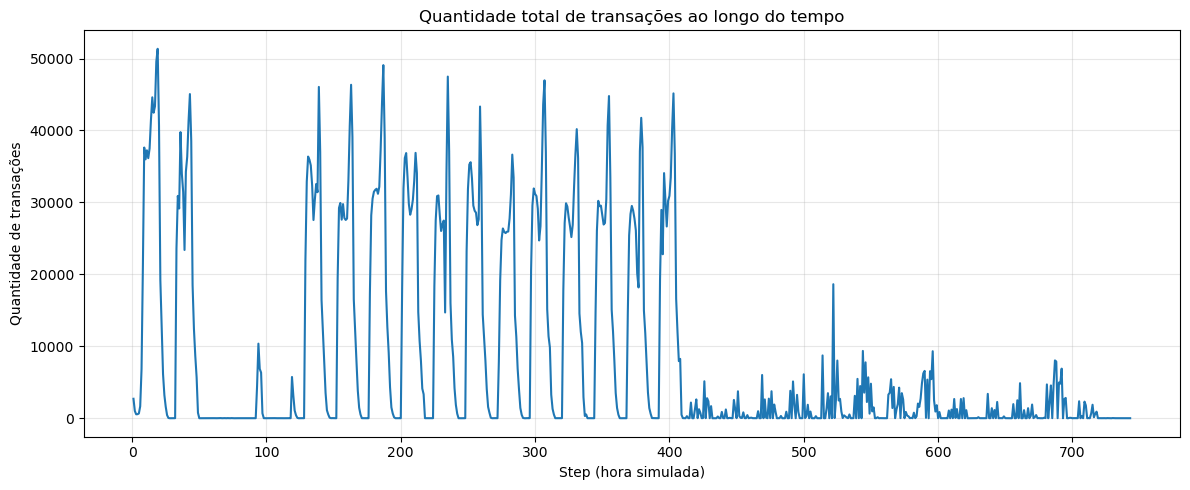

In [12]:

print("=== ANÁLISE DO FINAL DA SIMULAÇÃO ===")

# Último step contendo transação legítima
ultimo_step_legitimo = df_paysim.loc[
    df_paysim["isFraud"] == 0,
    "step"
].max()

# Primeiro e último step contendo fraude
steps_fraude = df_paysim.loc[
    df_paysim["isFraud"] == 1,
    "step"
]

print(
    "Último step com transação legítima:",
    ultimo_step_legitimo
)

print(
    "Primeiro step com fraude:",
    steps_fraude.min()
)

print(
    "Último step com fraude:",
    steps_fraude.max()
)

# Inspecionar os últimos 30 steps
resumo_final = tabela_temporal[
    tabela_temporal["step"] >= 714
].copy()

resumo_final["Legítimas"] = (
    resumo_final["Total"] -
    resumo_final["Fraudes"]
)

display(
    resumo_final[
        [
            "step",
            "Total",
            "Legítimas",
            "Fraudes",
            "Taxa de fraude (%)"
        ]
    ]
)

# Visualizar a quantidade de transações por step
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    tabela_temporal["step"],
    tabela_temporal["Total"]
)

ax.set_title(
    "Quantidade total de transações ao longo do tempo"
)
ax.set_xlabel("Step (hora simulada)")
ax.set_ylabel("Quantidade de transações")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


<h2>Célula 13 — Estatísticas dos valores das transações

In [13]:

print("=== ESTATÍSTICAS DOS VALORES DAS TRANSAÇÕES ===")

# Estatísticas gerais por classe
estatisticas_valores = (
    df_paysim.groupby("isFraud")["amount"]
    .agg(
        Quantidade="count",
        Media="mean",
        Mediana="median",
        Desvio_Padrao="std",
        Minimo="min",
        Maximo="max"
    )
)

display(estatisticas_valores.round(2))

# Quartis e percentis
print("\n=== DISTRIBUIÇÃO DOS VALORES POR CLASSE ===")

percentis_valores = (
    df_paysim.groupby("isFraud")["amount"]
    .quantile([0.25, 0.50, 0.75, 0.95, 0.99])
    .unstack()
)

percentis_valores.columns = [
    "P25", "P50", "P75", "P95", "P99"
]

display(percentis_valores.round(2))

# Valores iguais a zero e negativos
print("\n=== VERIFICAÇÃO DOS VALORES ===")

print(
    "Transações com valor zero:",
    (df_paysim["amount"] == 0).sum()
)

print(
    "Transações com valor negativo:",
    (df_paysim["amount"] < 0).sum()
)


=== ESTATÍSTICAS DOS VALORES DAS TRANSAÇÕES ===


,Quantidade,Media,Mediana,Desvio_Padrao,Minimo,Maximo
isFraud,,,,,,
0,6354407,178197.04,74684.72,596236.98,0.01,92445516.64
1,8213,1467967.30,441423.44,2404252.95,0.00,10000000.00



=== DISTRIBUIÇÃO DOS VALORES POR CLASSE ===


,P25,P50,P75,P95,P99
isFraud,,,,,
0,13368.40,74684.72,208364.76,515610.42,1586064.17
1,127091.33,441423.44,1517771.48,8006429.04,10000000.00



=== VERIFICAÇÃO DOS VALORES ===
Transações com valor zero: 16
Transações com valor negativo: 0


<h2>Célula 14 — Analisar os saldos das contas

In [14]:

print("=== ESTATÍSTICAS DOS SALDOS POR CLASSE ===")

colunas_saldos = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

# Médias dos saldos
print("\nMédias:")
display(
    df_paysim.groupby("isFraud")[colunas_saldos]
    .mean()
    .round(2)
)

# Medianas dos saldos
print("\nMedianas:")
display(
    df_paysim.groupby("isFraud")[colunas_saldos]
    .median()
    .round(2)
)

# Percentual de saldos iguais a zero
print("\nPercentual de saldos iguais a zero:")

percentual_zeros = (
    df_paysim[colunas_saldos]
    .eq(0)
    .groupby(df_paysim["isFraud"])
    .mean() * 100
)

display(percentual_zeros.round(2))

# Verificar saldos negativos
print("\nQuantidade de saldos negativos:")

display(
    df_paysim[colunas_saldos]
    .lt(0)
    .sum()
)


=== ESTATÍSTICAS DOS SALDOS POR CLASSE ===

Médias:


,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,832828.71,855970.23,1101420.87,1224925.68
1,1649667.61,192392.63,544249.62,1279707.62



Medianas:


,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,14069.00,0.0,133311.8,214881.70
1,438983.45,0.0,0.0,4676.42



Percentual de saldos iguais a zero:


,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,33.09,56.68,42.48,38.33
1,0.50,98.05,65.15,49.81



Quantidade de saldos negativos:


oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
dtype: int64

<h2>Célula 15 — Verificação das transações de valor zero

In [15]:

print("=== TRANSAÇÕES COM VALOR ZERO ===")

transacoes_zero = df_paysim.loc[
    df_paysim["amount"] == 0,
    ["step", "type", "amount", "isFraud", "isFlaggedFraud"]
]

print("Quantidade:", len(transacoes_zero))

print("\nDistribuição por classe:")
display(transacoes_zero["isFraud"].value_counts())

print("\nDistribuição por tipo:")
display(transacoes_zero["type"].value_counts())

print("\nRelação com isFlaggedFraud:")
display(
    pd.crosstab(
        transacoes_zero["isFraud"],
        transacoes_zero["isFlaggedFraud"]
    )
)

print("\nPrimeiros registros:")
display(transacoes_zero.head(10))


=== TRANSAÇÕES COM VALOR ZERO ===
Quantidade: 16

Distribuição por classe:


isFraud
1    16
Name: count, dtype: int64


Distribuição por tipo:


type
CASH_OUT    16
Name: count, dtype: int64


Relação com isFlaggedFraud:


isFlaggedFraud,0
isFraud,
1,16



Primeiros registros:


,step,type,amount,isFraud,isFlaggedFraud
2736447,212,CASH_OUT,0.0,1,0
3247298,250,CASH_OUT,0.0,1,0
3760289,279,CASH_OUT,0.0,1,0
5563714,387,CASH_OUT,0.0,1,0
5996408,425,CASH_OUT,0.0,1,0
5996410,425,CASH_OUT,0.0,1,0
6168500,554,CASH_OUT,0.0,1,0
6205440,586,CASH_OUT,0.0,1,0
6266414,617,CASH_OUT,0.0,1,0
6281483,646,CASH_OUT,0.0,1,0


<h2>Célula 16 — Verificação dos saldos por tipo

In [16]:

import numpy as np

# Analisar apenas transações de saída
tipos_saida = ["TRANSFER", "CASH_OUT", "PAYMENT", "DEBIT"]

df_saida = df_paysim.loc[
    df_paysim["type"].isin(tipos_saida),
    ["type", "isFraud", "amount",
     "oldbalanceOrg", "newbalanceOrig"]
].copy()

# Diferença entre a redução de saldo e o valor
df_saida["diferenca_saldo"] = (
    df_saida["oldbalanceOrg"]
    - df_saida["newbalanceOrig"]
    - df_saida["amount"]
)

# Tolerância para pequenas diferenças numéricas
TOLERANCIA = 0.01

df_saida["saldo_compativel"] = np.isclose(
    df_saida["diferenca_saldo"],
    0,
    atol=TOLERANCIA,
    rtol=0
)

print("=== CONSISTÊNCIA DO SALDO DE ORIGEM ===")

resumo_consistencia = (
    df_saida.groupby(["type", "isFraud"])
    .agg(
        Quantidade=("saldo_compativel", "size"),
        Compatíveis=("saldo_compativel", "sum")
    )
)

resumo_consistencia["Percentual compatível (%)"] = (
    resumo_consistencia["Compatíveis"]
    / resumo_consistencia["Quantidade"] * 100
)

display(resumo_consistencia.round(2))

# Liberar DataFrame auxiliar
del df_saida


=== CONSISTÊNCIA DO SALDO DE ORIGEM ===


Quantidade  Compatíveis  Percentual compatível (%)
type     isFraud                                                    
CASH_OUT 0           2233384       243070                      10.88
         1              4116         4092                      99.42
DEBIT    0             41432        29089                      70.21
PAYMENT  0           2151495       995783                      46.28
TRANSFER 0            528812        20085                       3.80
         1              4097         4076                      99.49

<h2>Célula 17 — Investigar as poucas fraudes com saldos incompatíveis

In [17]:

import numpy as np

print("=== EXCEÇÕES NA CONSISTÊNCIA DOS SALDOS ===")

# Selecionar apenas as transações fraudulentas
fraudes = df_paysim.loc[
    df_paysim["isFraud"] == 1,
    [
        "step",
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig"
    ]
].copy()

# Diferença entre redução do saldo e valor movimentado
fraudes["diferenca_saldo"] = (
    fraudes["oldbalanceOrg"]
    - fraudes["newbalanceOrig"]
    - fraudes["amount"]
)

# Identificar incompatibilidades
incompatíveis = fraudes.loc[
    ~np.isclose(
        fraudes["diferenca_saldo"],
        0,
        atol=0.01,
        rtol=0
    )
]

print("Fraudes incompatíveis:", len(incompatíveis))

print("\nPor tipo:")
display(incompatíveis["type"].value_counts())

print("\nQuantidade com amount = 0:")
print((incompatíveis["amount"] == 0).sum())

print("\nExemplos das incompatibilidades:")
display(incompatíveis.head(10))

print("\nResumo das diferenças absolutas:")
display(incompatíveis["diferenca_saldo"].abs().describe())

# Liberar cópias auxiliares
del fraudes, incompatíveis


=== EXCEÇÕES NA CONSISTÊNCIA DOS SALDOS ===
Fraudes incompatíveis: 45

Por tipo:


type
CASH_OUT    24
TRANSFER    21
Name: count, dtype: int64


Quantidade com amount = 0:
0

Exemplos das incompatibilidades:


,step,type,amount,oldbalanceOrg,newbalanceOrig,diferenca_saldo
724,1,CASH_OUT,416001.33,0.00,0.0,-416001.33
1911,1,CASH_OUT,132842.64,4499.08,0.0,-128343.56
14861,8,CASH_OUT,181728.11,0.00,0.0,-181728.11
25875,8,TRANSFER,1078013.76,0.00,0.0,-1078013.76
77745,10,CASH_OUT,277970.88,0.00,0.0,-277970.88
138559,11,TRANSFER,1933920.80,0.00,0.0,-1933920.80
169998,12,CASH_OUT,149668.66,0.00,0.0,-149668.66
178668,12,CASH_OUT,222048.71,0.00,0.0,-222048.71
200845,13,CASH_OUT,454859.39,0.00,0.0,-454859.39
217978,13,TRANSFER,123194.95,79466.45,0.0,-43728.50



Resumo das diferenças absolutas:


count    4.500000e+01
mean     1.951468e+06
std      3.040980e+06
min      2.329230e+04
25%      1.496687e+05
50%      3.990451e+05
75%      2.542664e+06
max      1.000000e+07
Name: diferenca_saldo, dtype: float64

<h2>Célula 18 — Preparar as variáveis e realizar a divisão

In [18]:

from sklearn.model_selection import train_test_split

# Atributos definidos para o experimento inicial
atributos = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg"
]

# Separar variáveis de entrada e alvo
X = df_paysim[atributos]
y = df_paysim["isFraud"]

# Divisão aleatória estratificada
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("=== DIVISÃO DOS DADOS ===")

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

print("\nDistribuição das classes no treinamento:")
display(
    y_treino.value_counts(normalize=True)
    .mul(100)
    .rename("Percentual (%)")
)

print("\nDistribuição das classes no teste:")
display(
    y_teste.value_counts(normalize=True)
    .mul(100)
    .rename("Percentual (%)")
)

print("\nQuantidade de fraudes no treinamento:")
print(y_treino.sum())

print("\nQuantidade de fraudes no teste:")
print(y_teste.sum())


=== DIVISÃO DOS DADOS ===
Treinamento: (5090096, 4)
Teste: (1272524, 4)

Distribuição das classes no treinamento:


isFraud
0    99.870926
1     0.129074
Name: Percentual (%), dtype: float64


Distribuição das classes no teste:


isFraud
0    99.870887
1     0.129113
Name: Percentual (%), dtype: float64


Quantidade de fraudes no treinamento:
6570

Quantidade de fraudes no teste:
1643


<h2>Célula 19 — Verificação da separação

In [19]:

print("=== VERIFICAÇÃO DA DIVISÃO ===")

# Verificar sobreposição de índices originais
indices_comuns = X_treino.index.intersection(X_teste.index)

print(
    "Índices presentes em treino e teste:",
    len(indices_comuns)
)

# Conferir se todos os registros foram distribuídos
total_dividido = len(X_treino) + len(X_teste)

print("Registros na base original:", len(df_paysim))
print("Registros após a divisão:", total_dividido)

# Conferir se X e y permanecem alinhados
print(
    "Índices alinhados no treinamento:",
    X_treino.index.equals(y_treino.index)
)

print(
    "Índices alinhados no teste:",
    X_teste.index.equals(y_teste.index)
)

# Confirmar ausência de valores ausentes
print(
    "Valores ausentes no treinamento:",
    X_treino.isna().sum().sum()
)

print(
    "Valores ausentes no teste:",
    X_teste.isna().sum().sum()
)

assert len(indices_comuns) == 0
assert total_dividido == len(df_paysim)
assert X_treino.index.equals(y_treino.index)
assert X_teste.index.equals(y_teste.index)

print("\nVerificações concluídas.")


=== VERIFICAÇÃO DA DIVISÃO ===
Índices presentes em treino e teste: 0
Registros na base original: 6362620
Registros após a divisão: 6362620
Índices alinhados no treinamento: True
Índices alinhados no teste: True
Valores ausentes no treinamento: 0
Valores ausentes no teste: 0

Verificações concluídas.


<h2>Célula 20 — Separar treinamento e validação

In [20]:

from sklearn.model_selection import train_test_split

# Criar validação interna exclusivamente a partir
# do conjunto de treinamento já separado
X_treino_interno, X_validacao, y_treino_interno, y_validacao = (
    train_test_split(
        X_treino,
        y_treino,
        test_size=0.20,
        stratify=y_treino,
        random_state=42
    )
)

print("=== DIVISÃO PARA DESENVOLVIMENTO ===")

print("Treinamento interno:", X_treino_interno.shape)
print("Validação:", X_validacao.shape)
print("Teste reservado:", X_teste.shape)

print("\n=== DISTRIBUIÇÃO DAS CLASSES ===")

for nome, y_conjunto in [
    ("Treinamento interno", y_treino_interno),
    ("Validação", y_validacao),
    ("Teste reservado", y_teste)
]:
    print(f"\n{nome}")
    print("Registros:", len(y_conjunto))
    print("Fraudes:", int(y_conjunto.sum()))
    print(
        "Percentual de fraudes:",
        f"{y_conjunto.mean() * 100:.6f}%"
    )

print("\n=== VERIFICAÇÃO DE SOBREPOSIÇÃO ===")

assert len(
    X_treino_interno.index.intersection(X_validacao.index)
) == 0

assert len(
    X_treino_interno.index.intersection(X_teste.index)
) == 0

assert len(
    X_validacao.index.intersection(X_teste.index)
) == 0

print("Nenhuma sobreposição de índices encontrada.")


=== DIVISÃO PARA DESENVOLVIMENTO ===
Treinamento interno: (4072076, 4)
Validação: (1018020, 4)
Teste reservado: (1272524, 4)

=== DISTRIBUIÇÃO DAS CLASSES ===

Treinamento interno
Registros: 4072076
Fraudes: 5256
Percentual de fraudes: 0.129074%

Validação
Registros: 1018020
Fraudes: 1314
Percentual de fraudes: 0.129074%

Teste reservado
Registros: 1272524
Fraudes: 1643
Percentual de fraudes: 0.129113%

=== VERIFICAÇÃO DE SOBREPOSIÇÃO ===
Nenhuma sobreposição de índices encontrada.


<h2>Célula 21 — Construir o pipeline da Regressão Logística

In [21]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import sklearn

print("Versão do scikit-learn:", sklearn.__version__)

# Atributos utilizados
atributos_numericos = [
    "step",
    "amount",
    "oldbalanceOrg"
]

atributos_categoricos = ["type"]

# Preparação dos dados
preprocessamento_rl = ColumnTransformer(
    transformers=[
        (
            "numericos",
            StandardScaler(),
            atributos_numericos
        ),
        (
            "categoricos",
            OneHotEncoder(handle_unknown="ignore"),
            atributos_categoricos
        )
    ]
)

# Regressão Logística sem ponderação
modelo_rl = Pipeline(
    steps=[
        ("preprocessamento", preprocessamento_rl),
        (
            "classificador",
            LogisticRegression(
                solver="lbfgs",
                max_iter=1000,
                class_weight=None,
                random_state=42
            )
        )
    ]
)

print("\nPipeline criado com sucesso!")
print(modelo_rl)


Versão do scikit-learn: 1.7.2

Pipeline criado com sucesso!
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericos', StandardScaler(),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg']),
                                                 ('categoricos',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classificador',
                 LogisticRegression(max_iter=1000, random_state=42))])


<h2>Célula 22 — Treinamento

In [22]:

import time
import warnings
from sklearn.exceptions import ConvergenceWarning

print("=== REGRESSÃO LOGÍSTICA: TREINAMENTO ===")

inicio = time.perf_counter()

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)

    modelo_rl.fit(
        X_treino_interno,
        y_treino_interno
    )

tempo_rl = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_rl:.2f} segundos")

print(
    "Iterações:",
    modelo_rl.named_steps["classificador"].n_iter_
)

for aviso in avisos:
    print(
        f"\nAviso ({aviso.category.__name__}): "
        f"{aviso.message}"
    )


=== REGRESSÃO LOGÍSTICA: TREINAMENTO ===
Treinamento concluído!
Tempo: 4.52 segundos
Iterações: [26]


<h2>Célula 23 — Avaliação na validação

In [23]:

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== REGRESSÃO LOGÍSTICA: VALIDAÇÃO ===")

# Probabilidades da classe fraudulenta
prob_rl = modelo_rl.predict_proba(
    X_validacao
)[:, 1]

# Limiar inicial de decisão: 0,5
pred_rl = (prob_rl >= 0.5).astype(int)

# Matriz de confusão
matriz_rl = confusion_matrix(
    y_validacao,
    pred_rl,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_rl.ravel()

print("\nMatriz de confusão:")
print(matriz_rl)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

# Métricas
metricas_rl = {
    "Acurácia": accuracy_score(
        y_validacao, pred_rl
    ),
    "Precisão": precision_score(
        y_validacao, pred_rl,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validacao, pred_rl,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validacao, pred_rl,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validacao, prob_rl
    ),
    "Average Precision (AP)": average_precision_score(
        y_validacao, prob_rl
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_rl.items():
    print(f"{nome}: {valor:.6f}")

print("\nFraudes reais na validação:", int(y_validacao.sum()))
print("Transações classificadas como fraude:", int(pred_rl.sum()))
print("Limiar utilizado: 0.5")


=== REGRESSÃO LOGÍSTICA: VALIDAÇÃO ===

Matriz de confusão:
[[1016665      41]
 [   1119     195]]

Verdadeiros negativos: 1016665
Falsos positivos: 41
Falsos negativos: 1119
Verdadeiros positivos: 195

=== MÉTRICAS ===
Acurácia: 0.998861
Precisão: 0.826271
Recall: 0.148402
F1-score: 0.251613
ROC-AUC: 0.935320
Average Precision (AP): 0.292641

Fraudes reais na validação: 1314
Transações classificadas como fraude: 236
Limiar utilizado: 0.5


<h2>Célula 24 — Treinar Regressão Logística com ponderação

In [24]:

from sklearn.base import clone
import time
import warnings
from sklearn.exceptions import ConvergenceWarning

# Criar uma cópia independente do pipeline anterior
modelo_rl_balanceado = clone(modelo_rl)

# Alterar somente a ponderação das classes
modelo_rl_balanceado.set_params(
    classificador__class_weight="balanced"
)

print("=== REGRESSÃO LOGÍSTICA COM PONDERAÇÃO ===")

inicio = time.perf_counter()

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)

    modelo_rl_balanceado.fit(
        X_treino_interno,
        y_treino_interno
    )

tempo_rl_balanceado = time.perf_counter() - inicio

print("Treinamento concluído!")
print(
    f"Tempo: {tempo_rl_balanceado:.2f} segundos"
)

print(
    "Iterações:",
    modelo_rl_balanceado.named_steps[
        "classificador"
    ].n_iter_
)

for aviso in avisos:
    print(
        f"\nAviso ({aviso.category.__name__}): "
        f"{aviso.message}"
    )


=== REGRESSÃO LOGÍSTICA COM PONDERAÇÃO ===
Treinamento concluído!
Tempo: 6.70 segundos
Iterações: [33]


<h2>Célula 25 — Avaliar na validação

In [25]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== REGRESSÃO LOGÍSTICA BALANCEADA: VALIDAÇÃO ===")

# Probabilidades de fraude
prob_rl_balanceado = modelo_rl_balanceado.predict_proba(
    X_validacao
)[:, 1]

# Limiar inicial de 0,5
pred_rl_balanceado = (
    prob_rl_balanceado >= 0.5
).astype(int)

# Matriz de confusão
matriz_rl_balanceado = confusion_matrix(
    y_validacao,
    pred_rl_balanceado,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_rl_balanceado.ravel()

print("\nMatriz de confusão:")
print(matriz_rl_balanceado)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

metricas_rl_balanceado = {
    "Acurácia": accuracy_score(
        y_validacao, pred_rl_balanceado
    ),
    "Precisão": precision_score(
        y_validacao, pred_rl_balanceado,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validacao, pred_rl_balanceado,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validacao, pred_rl_balanceado,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validacao, prob_rl_balanceado
    ),
    "Average Precision (AP)": average_precision_score(
        y_validacao, prob_rl_balanceado
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_rl_balanceado.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nFraudes reais na validação:",
    int(y_validacao.sum())
)

print(
    "Transações classificadas como fraude:",
    int(pred_rl_balanceado.sum())
)

print("Limiar utilizado: 0.5")


=== REGRESSÃO LOGÍSTICA BALANCEADA: VALIDAÇÃO ===

Matriz de confusão:
[[947768  68938]
 [   110   1204]]

Verdadeiros negativos: 947768
Falsos positivos: 68938
Falsos negativos: 110
Verdadeiros positivos: 1204

=== MÉTRICAS ===
Acurácia: 0.932174
Precisão: 0.017165
Recall: 0.916286
F1-score: 0.033699
ROC-AUC: 0.978420
Average Precision (AP): 0.162566

Fraudes reais na validação: 1314
Transações classificadas como fraude: 70142
Limiar utilizado: 0.5


<h2>Célula 26 — Criar o pipeline da Random Forest

In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Na Random Forest não precisamos padronizar
# as variáveis numéricas.

preprocessamento_rf = ColumnTransformer(
    transformers=[
        (
            "numericos",
            "passthrough",
            ["step", "amount", "oldbalanceOrg"]
        ),
        (
            "categoricos",
            OneHotEncoder(handle_unknown="ignore"),
            ["type"]
        )
    ]
)

modelo_rf = Pipeline(
    steps=[
        ("preprocessamento", preprocessamento_rf),
        (
            "classificador",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=12,
                min_samples_leaf=50,
                max_features="sqrt",
                class_weight=None,
                random_state=42,
                n_jobs=2
            )
        )
    ]
)

print("Pipeline da Random Forest criado!")
print(modelo_rf)


Pipeline da Random Forest criado!
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericos', 'passthrough',
                                                  ['step', 'amount',
                                                   'oldbalanceOrg']),
                                                 ('categoricos',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classificador',
                 RandomForestClassifier(max_depth=12, min_samples_leaf=50,
                                        n_jobs=2, random_state=42))])


<h2>Célula 27 — Treinar a Random Forest inicial

In [27]:

import time

print("=== RANDOM FOREST SEM PONDERAÇÃO ===")

inicio = time.perf_counter()

modelo_rf.fit(
    X_treino_interno,
    y_treino_interno
)

tempo_rf = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_rf:.2f} segundos")
print(
    "Quantidade de árvores:",
    len(
        modelo_rf.named_steps[
            "classificador"
        ].estimators_
    )
)


=== RANDOM FOREST SEM PONDERAÇÃO ===
Treinamento concluído!
Tempo: 253.88 segundos
Quantidade de árvores: 100


<h2>Célula 28 — Avaliar na validação

In [28]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== RANDOM FOREST: VALIDAÇÃO ===")

prob_rf = modelo_rf.predict_proba(
    X_validacao
)[:, 1]

pred_rf = (prob_rf >= 0.5).astype(int)

matriz_rf = confusion_matrix(
    y_validacao,
    pred_rf,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_rf.ravel()

print("\nMatriz de confusão:")
print(matriz_rf)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

metricas_rf = {
    "Acurácia": accuracy_score(
        y_validacao, pred_rf
    ),
    "Precisão": precision_score(
        y_validacao, pred_rf,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validacao, pred_rf,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validacao, pred_rf,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validacao, prob_rf
    ),
    "Average Precision (AP)": average_precision_score(
        y_validacao, prob_rf
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_rf.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nTransações classificadas como fraude:",
    int(pred_rf.sum())
)

print("Limiar utilizado: 0.5")


=== RANDOM FOREST: VALIDAÇÃO ===

Matriz de confusão:
[[1016695      11]
 [    785     529]]

Verdadeiros negativos: 1016695
Falsos positivos: 11
Falsos negativos: 785
Verdadeiros positivos: 529

=== MÉTRICAS ===
Acurácia: 0.999218
Precisão: 0.979630
Recall: 0.402588
F1-score: 0.570658
ROC-AUC: 0.995238
Average Precision (AP): 0.669726

Transações classificadas como fraude: 540
Limiar utilizado: 0.5


<h2>Célula 29 — Treinar a Random Forest ponderada

In [29]:

from sklearn.base import clone
import time

# Criar uma configuração independente
modelo_rf_balanceado = clone(modelo_rf)

# Alterar somente a ponderação das classes
modelo_rf_balanceado.set_params(
    classificador__class_weight="balanced"
)

print("=== RANDOM FOREST COM PONDERAÇÃO ===")

inicio = time.perf_counter()

modelo_rf_balanceado.fit(
    X_treino_interno,
    y_treino_interno
)

tempo_rf_balanceado = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_rf_balanceado:.2f} segundos")

print(
    "Quantidade de árvores:",
    len(
        modelo_rf_balanceado.named_steps[
            "classificador"
        ].estimators_
    )
)


=== RANDOM FOREST COM PONDERAÇÃO ===
Treinamento concluído!
Tempo: 222.59 segundos
Quantidade de árvores: 100


<h2>Célula 30 — Avaliar a Random Forest ponderada

In [30]:

print("=== RANDOM FOREST PONDERADA: VALIDAÇÃO ===")

# Probabilidades da classe fraudulenta
prob_rf_balanceado = modelo_rf_balanceado.predict_proba(
    X_validacao
)[:, 1]

# Limiar padrão
pred_rf_balanceado = (
    prob_rf_balanceado >= 0.5
).astype(int)

# Matriz de confusão
matriz_rf_balanceado = confusion_matrix(
    y_validacao,
    pred_rf_balanceado,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_rf_balanceado.ravel()

print("\nMatriz de confusão:")
print(matriz_rf_balanceado)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

# Métricas
metricas_rf_balanceado = {
    "Acurácia": accuracy_score(
        y_validacao,
        pred_rf_balanceado
    ),
    "Precisão": precision_score(
        y_validacao,
        pred_rf_balanceado,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validacao,
        pred_rf_balanceado,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validacao,
        pred_rf_balanceado,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validacao,
        prob_rf_balanceado
    ),
    "Average Precision (AP)": average_precision_score(
        y_validacao,
        prob_rf_balanceado
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_rf_balanceado.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nTransações classificadas como fraude:",
    int(pred_rf_balanceado.sum())
)

print("Limiar utilizado: 0.5")


=== RANDOM FOREST PONDERADA: VALIDAÇÃO ===

Matriz de confusão:
[[991493  25213]
 [    11   1303]]

Verdadeiros negativos: 991493
Falsos positivos: 25213
Falsos negativos: 11
Verdadeiros positivos: 1303

=== MÉTRICAS ===
Acurácia: 0.975222
Precisão: 0.049140
Recall: 0.991629
F1-score: 0.093640
ROC-AUC: 0.998563
Average Precision (AP): 0.785514

Transações classificadas como fraude: 26516
Limiar utilizado: 0.5


<h2>Célula 31 — Analisar limiares dos quatro modelos

In [31]:

import numpy as np
import pandas as pd

from sklearn.metrics import precision_recall_curve

# Escores calculados nas células anteriores
probabilidades_modelos = {
    "RL sem ponderação": prob_rl,
    "RL ponderada": prob_rl_balanceado,
    "RF sem ponderação": prob_rf,
    "RF ponderada": prob_rf_balanceado
}

resultados_limiares = []

for nome, probabilidades in probabilidades_modelos.items():

    precisao, recall, limiares = precision_recall_curve(
        y_validacao,
        probabilidades
    )

    # O último elemento de precisão/recall
    # não possui um limiar correspondente.
    p = precisao[:-1]
    r = recall[:-1]

    f1 = (
        2 * p * r /
        np.maximum(p + r, 1e-15)
    )

    # Limiar com maior F1 na validação
    indice_melhor_f1 = np.argmax(f1)

    melhor_limiar = limiares[indice_melhor_f1]

    # Cenário exploratório: precisão >= 80%
    candidatos = np.where(
        (p >= 0.80) & (r > 0)
    )[0]

    if len(candidatos) > 0:
        indice_precisao80 = candidatos[
            np.argmax(r[candidatos])
        ]

        limiar_precisao80 = limiares[indice_precisao80]
        recall_precisao80 = r[indice_precisao80]
    else:
        limiar_precisao80 = np.nan
        recall_precisao80 = np.nan

    resultados_limiares.append({
        "Modelo": nome,
        "Limiar melhor F1": melhor_limiar,
        "Melhor F1": f1[indice_melhor_f1],
        "Precisão no melhor F1": p[indice_melhor_f1],
        "Recall no melhor F1": r[indice_melhor_f1],
        "Limiar para precisão >= 80%": limiar_precisao80,
        "Recall com precisão >= 80%": recall_precisao80
    })

tabela_limiares = pd.DataFrame(resultados_limiares)

print("=== ANÁLISE DE LIMIARES NA VALIDAÇÃO ===")
display(tabela_limiares.round(6))


=== ANÁLISE DE LIMIARES NA VALIDAÇÃO ===


,Modelo,Limiar melhor F1,Melhor F1,Precisão no melhor F1,Recall no melhor F1,Limiar para precisão >= 80%,Recall com precisão >= 80%
0,RL sem ponderação,0.052629,0.397404,0.577649,0.302892,0.307851,0.171994
1,RL ponderada,0.999942,0.248257,0.318996,0.203196,NaN,NaN
2,RF sem ponderação,0.222728,0.652968,0.816210,0.544140,0.213259,0.547945
3,RF ponderada,0.943358,0.734930,0.803249,0.677321,0.943090,0.677321


<h2>Célula 32 — Visualizar a curva Precisão-Revocação

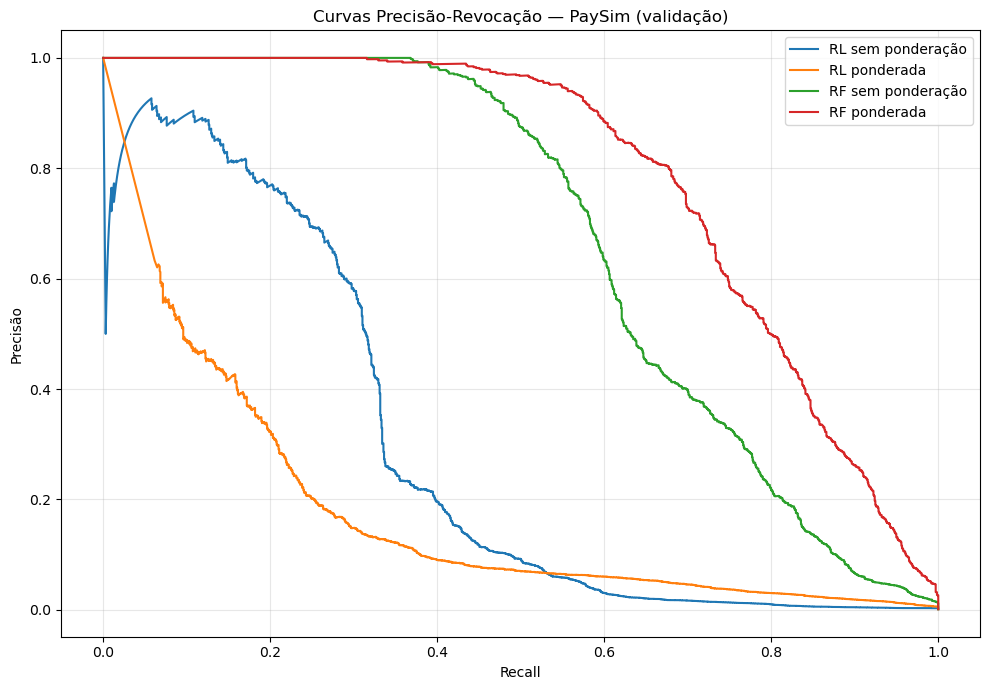

In [32]:

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 7))

for nome, probabilidades in probabilidades_modelos.items():

    precisao, recall, _ = precision_recall_curve(
        y_validacao,
        probabilidades
    )

    plt.plot(
        recall,
        precisao,
        label=nome
    )

plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title(
    "Curvas Precisão-Revocação — PaySim (validação)"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<h2>Célula 33 — Comparação com os limiares ajustados

In [33]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Reutilizar os limiares da célula 31.
# Nenhum modelo será treinado novamente.

resultados_ajustados = []

for _, linha in tabela_limiares.iterrows():

    nome = linha["Modelo"]
    limiar = linha["Limiar melhor F1"]
    probabilidades = probabilidades_modelos[nome]

    previsoes = (probabilidades >= limiar).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacao,
        previsoes,
        labels=[0, 1]
    ).ravel()

    resultados_ajustados.append({
        "Modelo": nome,
        "Limiar": limiar,
        "VP": tp,
        "FP": fp,
        "FN": fn,
        "VN": tn,
        "Precisão": precision_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_validacao, previsoes,
            zero_division=0
        )
    })

tabela_ajustada = pd.DataFrame(resultados_ajustados)

print("=== RESULTADOS COM LIMIARES AJUSTADOS ===")
display(tabela_ajustada.round(6))


=== RESULTADOS COM LIMIARES AJUSTADOS ===


,Modelo,Limiar,VP,FP,FN,VN,Precisão,Recall,F1-score
0,RL sem ponderação,0.052629,398,291,916,1016415,0.577649,0.302892,0.397404
1,RL ponderada,0.999942,267,570,1047,1016136,0.318996,0.203196,0.248257
2,RF sem ponderação,0.222728,715,161,599,1016545,0.816210,0.544140,0.652968
3,RF ponderada,0.943358,890,218,424,1016488,0.803249,0.677321,0.734930


<h2>Célula 34 — Avaliar limiares próximos

In [34]:

import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

limiares_teste = [
    0.85,
    0.90,
    0.92,
    0.94,
    0.943358,
    0.95,
    0.97,
    0.99
]

resultados_sensibilidade = []

for limiar in limiares_teste:

    previsoes = (
        prob_rf_balanceado >= limiar
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacao,
        previsoes,
        labels=[0, 1]
    ).ravel()

    resultados_sensibilidade.append({
        "Limiar": limiar,
        "VP": tp,
        "FP": fp,
        "FN": fn,
        "Precisão": precision_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_validacao, previsoes,
            zero_division=0
        )
    })

tabela_sensibilidade = pd.DataFrame(
    resultados_sensibilidade
)

print("=== SENSIBILIDADE DO LIMIAR — RF PONDERADA ===")

display(tabela_sensibilidade.round(6))


=== SENSIBILIDADE DO LIMIAR — RF PONDERADA ===


,Limiar,VP,FP,FN,Precisão,Recall,F1-score
0,0.850000,1071,1246,243,0.462236,0.815068,0.589920
1,0.900000,984,665,330,0.596725,0.748858,0.664192
2,0.920000,950,445,364,0.681004,0.722983,0.701366
3,0.940000,900,261,414,0.775194,0.684932,0.727273
4,0.943358,889,218,425,0.803071,0.676560,0.734407
5,0.950000,851,184,463,0.822222,0.647641,0.724564
6,0.970000,702,35,612,0.952510,0.534247,0.684544
7,0.990000,499,4,815,0.992048,0.379756,0.549257


<h2>Célula 35 — Conferir o limiar exato

In [35]:

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Recuperar o limiar original, sem arredondamento
limiar_exato = tabela_limiares.loc[
    tabela_limiares["Modelo"] == "RF ponderada",
    "Limiar melhor F1"
].iloc[0]

print("=== CONFERÊNCIA DO LIMIAR ===")

print(
    "Limiar exato:",
    repr(float(limiar_exato))
)

print(
    "Limiar arredondado:",
    repr(0.943358)
)

print(
    "Diferença:",
    float(limiar_exato) - 0.943358
)

pred_exato = (
    prob_rf_balanceado >= limiar_exato
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_validacao,
    pred_exato,
    labels=[0, 1]
).ravel()

print("\nMatriz de confusão com limiar exato:")
print(confusion_matrix(
    y_validacao,
    pred_exato,
    labels=[0, 1]
))

print("\nPrecisão:", precision_score(
    y_validacao, pred_exato
))

print("Recall:", recall_score(
    y_validacao, pred_exato
))

print("F1-score:", f1_score(
    y_validacao, pred_exato
))

print("\nVP:", tp)
print("FP:", fp)
print("FN:", fn)
print("VN:", tn)


=== CONFERÊNCIA DO LIMIAR ===
Limiar exato: 0.9433578705323871
Limiar arredondado: 0.943358
Diferença: -1.2946761296372955e-07

Matriz de confusão com limiar exato:
[[1016488     218]
 [    424     890]]

Precisão: 0.8032490974729242
Recall: 0.6773211567732116
F1-score: 0.7349298100743188

VP: 890
FP: 218
FN: 424
VN: 1016488


In [36]:
# ============================================================
# PARTE 2 — CREDIT CARD FRAUD DETECTION
# ANÁLISE EXPLORATÓRIA
# ============================================================

<h2>Célula 36 — Carregamento e estrutura da CreditCard

In [37]:

import pandas as pd
from pathlib import Path

# Caminho da base de dados
caminho_creditcard = Path(
    r"C:\Users\Caio\Desktop\Datasets\CreditCard.csv"
)

# Verificar existência do arquivo
if not caminho_creditcard.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {caminho_creditcard}"
    )

# Carregar a base completa
df_creditcard = pd.read_csv(caminho_creditcard)

print("=== CREDIT CARD FRAUD DETECTION ===")

print("\nBase carregada com sucesso!")

print("\nDimensões:")
print(df_creditcard.shape)

print("\nMemória utilizada:")
print(
    f"{df_creditcard.memory_usage(deep=True).sum() / 1024**2:.2f} MiB"
)

print("\nInformações gerais:")
df_creditcard.info()

print("\nPrimeiros registros:")
display(df_creditcard.head())


=== CREDIT CARD FRAUD DETECTION ===

Base carregada com sucesso!

Dimensões:
(284807, 31)

Memória utilizada:
67.36 MiB

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-nu

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<h2>Célula 37 — Qualidade dos dados e distribuição das classes

In [38]:

print("=== VALORES AUSENTES ===")

ausentes = pd.DataFrame({
    "Quantidade": df_creditcard.isna().sum(),
    "Percentual (%)": (
        df_creditcard.isna().mean() * 100
    )
})

display(ausentes)

print("\n=== DISTRIBUIÇÃO DAS CLASSES ===")

distribuicao = (
    df_creditcard["Class"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .reset_index(name="Quantidade")
)

distribuicao["Percentual (%)"] = (
    distribuicao["Quantidade"]
    / len(df_creditcard) * 100
)

display(distribuicao)

print("\n=== DUPLICATAS ===")

duplicatas = df_creditcard.duplicated().sum()

print("Registros duplicados:", duplicatas)

print(
    "Percentual de duplicatas:",
    f"{duplicatas / len(df_creditcard) * 100:.4f}%"
)

print("\n=== INTERVALO TEMPORAL ===")

print("Time mínimo:", df_creditcard["Time"].min())
print("Time máximo:", df_creditcard["Time"].max())

print("\n=== VALORES DAS TRANSAÇÕES ===")

display(
    df_creditcard.groupby("Class")["Amount"]
    .describe()
)


=== VALORES AUSENTES ===


,Quantidade,Percentual (%)
Time,0,0.0
V1,0,0.0
V2,0,0.0
V3,0,0.0
V4,0,0.0
V5,0,0.0
V6,0,0.0
V7,0,0.0
V8,0,0.0
V9,0,0.0



=== DISTRIBUIÇÃO DAS CLASSES ===


,Class,Quantidade,Percentual (%)
0,0,284315,99.827251
1,1,492,0.172749



=== DUPLICATAS ===
Registros duplicados: 1081
Percentual de duplicatas: 0.3796%

=== INTERVALO TEMPORAL ===
Time mínimo: 0.0
Time máximo: 172792.0

=== VALORES DAS TRANSAÇÕES ===


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


<h2>Célula 38 — Investigar duplicatas por classe

In [39]:

print("=== ANÁLISE DAS DUPLICATAS ===")

# Linhas que repetem uma ocorrência anterior
duplicadas = df_creditcard.duplicated(keep="first")

print("Duplicatas excedentes:", int(duplicadas.sum()))

print("\nDuplicatas excedentes por classe:")
display(
    df_creditcard.loc[duplicadas, "Class"]
    .value_counts()
    .sort_index()
)

# Inclui todas as ocorrências dos grupos repetidos
grupos_duplicados = df_creditcard.duplicated(
    keep=False
)

print("\nTotal de linhas pertencentes a grupos duplicados:")
print(int(grupos_duplicados.sum()))

print("\nPor classe:")
display(
    df_creditcard.loc[grupos_duplicados, "Class"]
    .value_counts()
    .sort_index()
)

print("\nDistribuição de classes após remoção hipotética:")
df_unico_analise = df_creditcard.drop_duplicates()

display(
    df_unico_analise["Class"]
    .value_counts()
    .sort_index()
)

# Não modificar a base original
del df_unico_analise


=== ANÁLISE DAS DUPLICATAS ===
Duplicatas excedentes: 1081

Duplicatas excedentes por classe:


Class
0    1062
1      19
Name: count, dtype: int64


Total de linhas pertencentes a grupos duplicados:
1854

Por classe:


Class
0    1822
1      32
Name: count, dtype: int64


Distribuição de classes após remoção hipotética:


Class
0    283253
1       473
Name: count, dtype: int64

<h2>Célula 39 — Verificar atributos iguais com rótulos diferentes

In [40]:

print("=== VERIFICAÇÃO DE RÓTULOS CONFLITANTES ===")

# Todas as colunas, exceto o alvo
atributos_creditcard = [
    coluna for coluna in df_creditcard.columns
    if coluna != "Class"
]

# Verificar registros com entradas idênticas
grupos = df_creditcard.groupby(
    atributos_creditcard,
    dropna=False
)["Class"]

# Quantidade de classes distintas por grupo
classes_distintas = grupos.nunique()

conflitos = classes_distintas[
    classes_distintas > 1
]

print(
    "Grupos com atributos iguais e classes diferentes:",
    len(conflitos)
)

print(
    "Grupos com atributos repetidos:",
    int((grupos.size() > 1).sum())
)


=== VERIFICAÇÃO DE RÓTULOS CONFLITANTES ===
Grupos com atributos iguais e classes diferentes: 0
Grupos com atributos repetidos: 773


<h2>Célula 40 — Remover duplicatas exatas

In [41]:

print("=== PREPARAÇÃO DA CREDITCARD ===")

# Preservar a base original
# e criar uma versão sem registros idênticos
df_creditcard_limpo = (
    df_creditcard
    .drop_duplicates()
    .copy()
)

# Reorganizar os índices
df_creditcard_limpo.reset_index(
    drop=True,
    inplace=True
)

print("Registros originais:", len(df_creditcard))

print(
    "Registros após remoção:",
    len(df_creditcard_limpo)
)

print(
    "Registros removidos:",
    len(df_creditcard) - len(df_creditcard_limpo)
)

print("\nDistribuição das classes:")

distribuicao_limpa = (
    df_creditcard_limpo["Class"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .reset_index(name="Quantidade")
)

distribuicao_limpa["Percentual (%)"] = (
    distribuicao_limpa["Quantidade"] /
    len(df_creditcard_limpo) * 100
)

display(distribuicao_limpa)

print("\nDuplicatas restantes:")
print(df_creditcard_limpo.duplicated().sum())

print("\nValores ausentes:")
print(df_creditcard_limpo.isna().sum().sum())


=== PREPARAÇÃO DA CREDITCARD ===
Registros originais: 284807
Registros após remoção: 283726
Registros removidos: 1081

Distribuição das classes:


,Class,Quantidade,Percentual (%)
0,0,283253,99.83329
1,1,473,0.16671



Duplicatas restantes:
0

Valores ausentes:
0


<h2>Célula 41 — Análise temporal da CreditCard

=== DISTRIBUIÇÃO TEMPORAL ===
Quantidade de intervalos horários: 48
Intervalos com fraudes: 46
Intervalos sem fraudes: 2


,Hora,Total,Fraudes,Legítimas,Taxa de fraude (%)
0,0,3931,2,3929,0.050878
1,1,2213,2,2211,0.090375
2,2,1573,21,1552,1.335029
3,3,1818,13,1805,0.715072
4,4,1082,6,1076,0.554529
5,5,1679,11,1668,0.655152
6,6,1822,3,1819,0.164654
7,7,3366,23,3343,0.683304
8,8,5148,5,5143,0.097125
9,9,7841,15,7826,0.191302


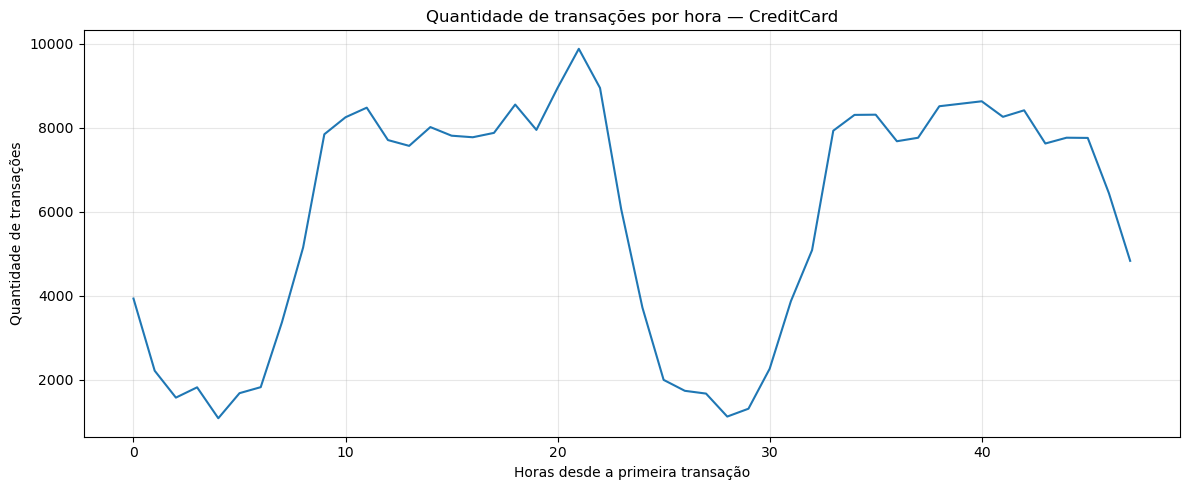

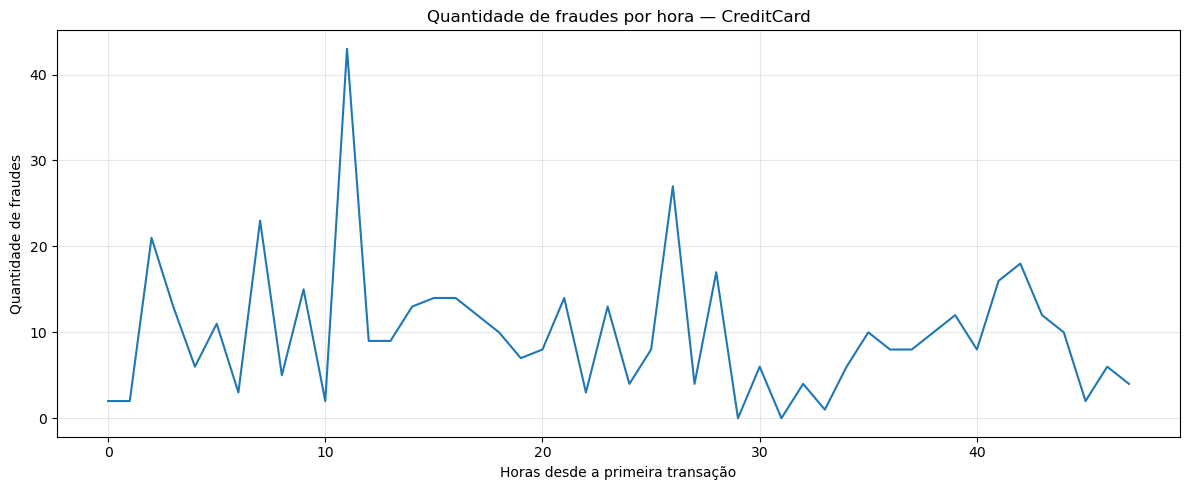

In [42]:

import matplotlib.pyplot as plt

# Criar um resumo temporal sem alterar a base
df_temporal_creditcard = df_creditcard_limpo[
    ["Time", "Class"]
].copy()

# Converter segundos em intervalos de horas
df_temporal_creditcard["Hora"] = (
    df_temporal_creditcard["Time"] // 3600
).astype(int)

resumo_temporal_creditcard = (
    df_temporal_creditcard.groupby("Hora")["Class"]
    .agg(
        Total="count",
        Fraudes="sum"
    )
    .reset_index()
)

resumo_temporal_creditcard["Legítimas"] = (
    resumo_temporal_creditcard["Total"] -
    resumo_temporal_creditcard["Fraudes"]
)

resumo_temporal_creditcard["Taxa de fraude (%)"] = (
    resumo_temporal_creditcard["Fraudes"] /
    resumo_temporal_creditcard["Total"] * 100
)

print("=== DISTRIBUIÇÃO TEMPORAL ===")

print(
    "Quantidade de intervalos horários:",
    len(resumo_temporal_creditcard)
)

print(
    "Intervalos com fraudes:",
    (resumo_temporal_creditcard["Fraudes"] > 0).sum()
)

print(
    "Intervalos sem fraudes:",
    (resumo_temporal_creditcard["Fraudes"] == 0).sum()
)

display(resumo_temporal_creditcard)

# Quantidade total de transações por hora
plt.figure(figsize=(12, 5))

plt.plot(
    resumo_temporal_creditcard["Hora"],
    resumo_temporal_creditcard["Total"]
)

plt.title(
    "Quantidade de transações por hora — CreditCard"
)
plt.xlabel("Horas desde a primeira transação")
plt.ylabel("Quantidade de transações")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Quantidade de fraudes por hora
plt.figure(figsize=(12, 5))

plt.plot(
    resumo_temporal_creditcard["Hora"],
    resumo_temporal_creditcard["Fraudes"]
)

plt.title(
    "Quantidade de fraudes por hora — CreditCard"
)
plt.xlabel("Horas desde a primeira transação")
plt.ylabel("Quantidade de fraudes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<h2>Célula 42 — Simular cortes temporais

In [43]:

print("=== SIMULAÇÃO DE DIVISÕES TEMPORAIS ===")

for proporcao_treino in [0.70, 0.80]:

    limite_time = df_creditcard_limpo["Time"].quantile(
        proporcao_treino
    )

    mascara_treino = (
        df_creditcard_limpo["Time"] <= limite_time
    )

    mascara_teste = (
        df_creditcard_limpo["Time"] > limite_time
    )

    total_treino = mascara_treino.sum()
    total_teste = mascara_teste.sum()

    fraudes_treino = df_creditcard_limpo.loc[
        mascara_treino, "Class"
    ].sum()

    fraudes_teste = df_creditcard_limpo.loc[
        mascara_teste, "Class"
    ].sum()

    print(
        f"\n--- Corte temporal próximo de "
        f"{proporcao_treino:.0%} / "
        f"{1-proporcao_treino:.0%} ---"
    )

    print(
        f"Time de corte: {limite_time:.2f} segundos"
    )

    print("\nPeríodo inicial:")
    print("Registros:", total_treino)
    print("Fraudes:", int(fraudes_treino))
    print(
        "Taxa de fraude:",
        f"{fraudes_treino / total_treino * 100:.6f}%"
    )

    print("\nPeríodo posterior:")
    print("Registros:", total_teste)
    print("Fraudes:", int(fraudes_teste))
    print(
        "Taxa de fraude:",
        f"{fraudes_teste / total_teste * 100:.6f}%"
    )


=== SIMULAÇÃO DE DIVISÕES TEMPORAIS ===

--- Corte temporal próximo de 70% / 30% ---
Time de corte: 132906.00 segundos

Período inicial:
Registros: 198609
Fraudes: 366
Taxa de fraude: 0.184282%

Período posterior:
Registros: 85117
Fraudes: 107
Taxa de fraude: 0.125709%

--- Corte temporal próximo de 80% / 20% ---
Time de corte: 145234.00 segundos

Período inicial:
Registros: 226982
Fraudes: 399
Taxa de fraude: 0.175785%

Período posterior:
Registros: 56744
Fraudes: 74
Taxa de fraude: 0.130410%


<h2>Célula 43 — Distribuição de Amount

In [44]:

print("=== DISTRIBUIÇÃO DOS VALORES — CREDITCARD ===")

percentis = (
    df_creditcard_limpo.groupby("Class")["Amount"]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
)

percentis.columns = [
    "P25", "P50", "P75", "P90", "P95", "P99"
]

display(percentis.round(2))

print("\n=== VALORES IGUAIS A ZERO ===")

tabela_zeros = pd.crosstab(
    df_creditcard_limpo["Class"],
    df_creditcard_limpo["Amount"] == 0
)

tabela_zeros.columns = [
    "Amount diferente de zero",
    "Amount igual a zero"
]

display(tabela_zeros)

print("\n=== VALORES NEGATIVOS ===")

print(
    "Quantidade:",
    int((df_creditcard_limpo["Amount"] < 0).sum())
)

print("\n=== DISTRIBUIÇÃO TEMPORAL POR CLASSE ===")

display(
    df_creditcard_limpo.groupby("Class")["Time"]
    .agg(["min", "median", "max"])
)


=== DISTRIBUIÇÃO DOS VALORES — CREDITCARD ===


,P25,P50,P75,P90,P95,P99
Class,,,,,,
0,5.67,22.00,77.46,203.00,365.00,1018.06
1,1.00,9.82,105.89,348.65,655.82,1364.14



=== VALORES IGUAIS A ZERO ===


,Amount diferente de zero,Amount igual a zero
Class,,
0,281470,1783
1,448,25



=== VALORES NEGATIVOS ===
Quantidade: 0

=== DISTRIBUIÇÃO TEMPORAL POR CLASSE ===


,min,median,max
Class,,,
0,0.0,84711.0,172792.0
1,406.0,73408.0,170348.0


<h2>Célula 44 — Separar a CreditCard em treinamento, validação e teste

In [45]:

from sklearn.model_selection import train_test_split

print("=== DIVISÃO DA CREDITCARD ===")

# Selecionar os 30 atributos preditores
atributos_creditcard = [
    coluna
    for coluna in df_creditcard_limpo.columns
    if coluna != "Class"
]

X_cc = df_creditcard_limpo[atributos_creditcard]
y_cc = df_creditcard_limpo["Class"]

# Primeira divisão: 80% desenvolvimento, 20% teste
X_cc_desenvolvimento, X_cc_teste, y_cc_desenvolvimento, y_cc_teste = (
    train_test_split(
        X_cc,
        y_cc,
        test_size=0.20,
        stratify=y_cc,
        random_state=42
    )
)

# Segunda divisão: 80% treino interno, 20% validação
X_cc_treino, X_cc_validacao, y_cc_treino, y_cc_validacao = (
    train_test_split(
        X_cc_desenvolvimento,
        y_cc_desenvolvimento,
        test_size=0.20,
        stratify=y_cc_desenvolvimento,
        random_state=42
    )
)

print("Quantidade de atributos:", len(atributos_creditcard))

print("\n=== DISTRIBUIÇÃO DOS CONJUNTOS ===")

for nome, X_conjunto, y_conjunto in [
    ("Treinamento interno", X_cc_treino, y_cc_treino),
    ("Validação", X_cc_validacao, y_cc_validacao),
    ("Teste reservado", X_cc_teste, y_cc_teste)
]:
    print(f"\n{nome}:")
    print("Dimensões:", X_conjunto.shape)
    print("Fraudes:", int(y_conjunto.sum()))
    print(
        "Taxa de fraude:",
        f"{y_conjunto.mean() * 100:.6f}%"
    )

print("\n=== VERIFICAÇÕES ===")

assert len(
    X_cc_treino.index.intersection(
        X_cc_validacao.index
    )
) == 0

assert len(
    X_cc_treino.index.intersection(
        X_cc_teste.index
    )
) == 0

assert len(
    X_cc_validacao.index.intersection(
        X_cc_teste.index
    )
) == 0

assert (
    len(X_cc_treino)
    + len(X_cc_validacao)
    + len(X_cc_teste)
    == len(df_creditcard_limpo)
)

assert X_cc_treino.index.equals(y_cc_treino.index)
assert X_cc_validacao.index.equals(y_cc_validacao.index)
assert X_cc_teste.index.equals(y_cc_teste.index)

print("Verificações concluídas com sucesso.")


=== DIVISÃO DA CREDITCARD ===
Quantidade de atributos: 30

=== DISTRIBUIÇÃO DOS CONJUNTOS ===

Treinamento interno:
Dimensões: (181584, 30)
Fraudes: 302
Taxa de fraude: 0.166314%

Validação:
Dimensões: (45396, 30)
Fraudes: 76
Taxa de fraude: 0.167416%

Teste reservado:
Dimensões: (56746, 30)
Fraudes: 95
Taxa de fraude: 0.167413%

=== VERIFICAÇÕES ===
Verificações concluídas com sucesso.


<h2>Célula 45 — Criar o pipeline da Regressão Logística

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== CREDITCARD: RANDOM FOREST — VALIDAÇÃO ===")

prob_cc_rf = modelo_cc_rf.predict_proba(
    X_cc_validacao
)[:, 1]

pred_cc_rf = (prob_cc_rf >= 0.5).astype(int)

matriz_cc_rf = confusion_matrix(
    y_cc_validacao,
    pred_cc_rf,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_cc_rf.ravel()

print("\nMatriz de confusão:")
print(matriz_cc_rf)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

metricas_cc_rf = {
    "Acurácia": accuracy_score(
        y_cc_validacao, pred_cc_rf
    ),
    "Precisão": precision_score(
        y_cc_validacao, pred_cc_rf,
        zero_division=0
    ),
    "Recall": recall_score(
        y_cc_validacao, pred_cc_rf,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_cc_validacao, pred_cc_rf,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_cc_validacao, prob_cc_rf
    ),
    "Average Precision (AP)": average_precision_score(
        y_cc_validacao, prob_cc_rf
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_cc_rf.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nFraudes reais na validação:",
    int(y_cc_validacao.sum())
)

print(
    "Transações classificadas como fraude:",
    int(pred_cc_rf.sum())
)

print("Limiar utilizado: 0.5")


=== CREDITCARD: RANDOM FOREST — VALIDAÇÃO ===

Matriz de confusão:
[[45313     7]
 [   25    51]]

Verdadeiros negativos: 45313
Falsos positivos: 7
Falsos negativos: 25
Verdadeiros positivos: 51

=== MÉTRICAS ===
Acurácia: 0.999295
Precisão: 0.879310
Recall: 0.671053
F1-score: 0.761194
ROC-AUC: 0.961411
Average Precision (AP): 0.824302

Fraudes reais na validação: 76
Transações classificadas como fraude: 58
Limiar utilizado: 0.5


In [46]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Regressão Logística sem ponderação de classes
modelo_cc_rl = Pipeline(
    steps=[
        (
            "padronizacao",
            StandardScaler()
        ),
        (
            "classificador",
            LogisticRegression(
                solver="lbfgs",
                max_iter=1000,
                class_weight=None,
                random_state=42
            )
        )
    ]
)

print("=== PIPELINE DA REGRESSÃO LOGÍSTICA ===")
print(modelo_cc_rl)


=== PIPELINE DA REGRESSÃO LOGÍSTICA ===
Pipeline(steps=[('padronizacao', StandardScaler()),
                ('classificador',
                 LogisticRegression(max_iter=1000, random_state=42))])


<h2>Célula 46 — Treinar o modelo

In [47]:

import time
import warnings
from sklearn.exceptions import ConvergenceWarning

print("=== CREDITCARD: REGRESSÃO LOGÍSTICA SEM PONDERAÇÃO ===")

inicio = time.perf_counter()

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)

    modelo_cc_rl.fit(
        X_cc_treino,
        y_cc_treino
    )

tempo_cc_rl = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_cc_rl:.2f} segundos")

print(
    "Iterações:",
    modelo_cc_rl.named_steps[
        "classificador"
    ].n_iter_
)

for aviso in avisos:
    print(
        f"\nAviso ({aviso.category.__name__}): "
        f"{aviso.message}"
    )


=== CREDITCARD: REGRESSÃO LOGÍSTICA SEM PONDERAÇÃO ===
Treinamento concluído!
Tempo: 0.35 segundos
Iterações: [18]


<h2>Célula 47 — Avaliar na validação

In [48]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== CREDITCARD: REGRESSÃO LOGÍSTICA — VALIDAÇÃO ===")

# Pontuações da classe fraudulenta
prob_cc_rl = modelo_cc_rl.predict_proba(
    X_cc_validacao
)[:, 1]

# Limiar inicial de 0,5
pred_cc_rl = (prob_cc_rl >= 0.5).astype(int)

# Matriz de confusão
matriz_cc_rl = confusion_matrix(
    y_cc_validacao,
    pred_cc_rl,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_cc_rl.ravel()

print("\nMatriz de confusão:")
print(matriz_cc_rl)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

metricas_cc_rl = {
    "Acurácia": accuracy_score(
        y_cc_validacao, pred_cc_rl
    ),
    "Precisão": precision_score(
        y_cc_validacao, pred_cc_rl,
        zero_division=0
    ),
    "Recall": recall_score(
        y_cc_validacao, pred_cc_rl,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_cc_validacao, pred_cc_rl,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_cc_validacao, prob_cc_rl
    ),
    "Average Precision (AP)": average_precision_score(
        y_cc_validacao, prob_cc_rl
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_cc_rl.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nFraudes reais na validação:",
    int(y_cc_validacao.sum())
)

print(
    "Transações classificadas como fraude:",
    int(pred_cc_rl.sum())
)

print("Limiar utilizado: 0.5")


=== CREDITCARD: REGRESSÃO LOGÍSTICA — VALIDAÇÃO ===

Matriz de confusão:
[[45315     5]
 [   24    52]]

Verdadeiros negativos: 45315
Falsos positivos: 5
Falsos negativos: 24
Verdadeiros positivos: 52

=== MÉTRICAS ===
Acurácia: 0.999361
Precisão: 0.912281
Recall: 0.684211
F1-score: 0.781955
ROC-AUC: 0.968462
Average Precision (AP): 0.822566

Fraudes reais na validação: 76
Transações classificadas como fraude: 57
Limiar utilizado: 0.5


<h2>Célula 48 — Treinar a Regressão Logística ponderada

In [49]:

from sklearn.base import clone
import time
import warnings
from sklearn.exceptions import ConvergenceWarning

# Criar uma cópia independente do modelo anterior
modelo_cc_rl_balanceado = clone(modelo_cc_rl)

# Alterar somente a ponderação das classes
modelo_cc_rl_balanceado.set_params(
    classificador__class_weight="balanced"
)

print("=== CREDITCARD: REGRESSÃO LOGÍSTICA PONDERADA ===")

inicio = time.perf_counter()

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)

    modelo_cc_rl_balanceado.fit(
        X_cc_treino,
        y_cc_treino
    )

tempo_cc_rl_balanceado = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_cc_rl_balanceado:.2f} segundos")

print(
    "Iterações:",
    modelo_cc_rl_balanceado.named_steps[
        "classificador"
    ].n_iter_
)

for aviso in avisos:
    print(
        f"\nAviso ({aviso.category.__name__}): "
        f"{aviso.message}"
    )


=== CREDITCARD: REGRESSÃO LOGÍSTICA PONDERADA ===
Treinamento concluído!
Tempo: 0.62 segundos
Iterações: [39]


<h2>Célula 49 — Avaliar na validação

In [50]:

print("=== CREDITCARD: RL PONDERADA — VALIDAÇÃO ===")

# Probabilidades da classe fraudulenta
prob_cc_rl_balanceado = (
    modelo_cc_rl_balanceado.predict_proba(
        X_cc_validacao
    )[:, 1]
)

# Aplicar limiar inicial de 0,5
pred_cc_rl_balanceado = (
    prob_cc_rl_balanceado >= 0.5
).astype(int)

# Matriz de confusão
matriz_cc_rl_balanceado = confusion_matrix(
    y_cc_validacao,
    pred_cc_rl_balanceado,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_cc_rl_balanceado.ravel()

print("\nMatriz de confusão:")
print(matriz_cc_rl_balanceado)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

# Métricas
metricas_cc_rl_balanceado = {
    "Acurácia": accuracy_score(
        y_cc_validacao,
        pred_cc_rl_balanceado
    ),
    "Precisão": precision_score(
        y_cc_validacao,
        pred_cc_rl_balanceado,
        zero_division=0
    ),
    "Recall": recall_score(
        y_cc_validacao,
        pred_cc_rl_balanceado,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_cc_validacao,
        pred_cc_rl_balanceado,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_cc_validacao,
        prob_cc_rl_balanceado
    ),
    "Average Precision (AP)": average_precision_score(
        y_cc_validacao,
        prob_cc_rl_balanceado
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_cc_rl_balanceado.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nFraudes reais na validação:",
    int(y_cc_validacao.sum())
)

print(
    "Transações classificadas como fraude:",
    int(pred_cc_rl_balanceado.sum())
)

print("Limiar utilizado: 0.5")


=== CREDITCARD: RL PONDERADA — VALIDAÇÃO ===

Matriz de confusão:
[[44134  1186]
 [    8    68]]

Verdadeiros negativos: 44134
Falsos positivos: 1186
Falsos negativos: 8
Verdadeiros positivos: 68

=== MÉTRICAS ===
Acurácia: 0.973698
Precisão: 0.054226
Recall: 0.894737
F1-score: 0.102256
ROC-AUC: 0.974914
Average Precision (AP): 0.813880

Fraudes reais na validação: 76
Transações classificadas como fraude: 1254
Limiar utilizado: 0.5


<h2>Célula 50 — Criar o pipeline da Random Forest

In [51]:

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

print("=== CREDITCARD: PIPELINE RANDOM FOREST ===")

# Todos os atributos da CreditCard já são numéricos.
# Não é necessário aplicar OneHotEncoder.
# Também não padronizaremos os atributos para a RF.

modelo_cc_rf = Pipeline(
    steps=[
        (
            "classificador",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=12,
                min_samples_leaf=50,
                max_features="sqrt",
                class_weight=None,
                random_state=42,
                n_jobs=2
            )
        )
    ]
)

print(modelo_cc_rf)


=== CREDITCARD: PIPELINE RANDOM FOREST ===
Pipeline(steps=[('classificador',
                 RandomForestClassifier(max_depth=12, min_samples_leaf=50,
                                        n_jobs=2, random_state=42))])


<h2>Célula 51 — Treinar a Random Forest

In [52]:

import time

print("=== CREDITCARD: RANDOM FOREST SEM PONDERAÇÃO ===")

inicio = time.perf_counter()

modelo_cc_rf.fit(
    X_cc_treino,
    y_cc_treino
)

tempo_cc_rf = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_cc_rf:.2f} segundos")

print(
    "Quantidade de árvores:",
    len(
        modelo_cc_rf.named_steps[
            "classificador"
        ].estimators_
    )
)


=== CREDITCARD: RANDOM FOREST SEM PONDERAÇÃO ===
Treinamento concluído!
Tempo: 52.65 segundos
Quantidade de árvores: 100


<h2>Célula 52 — Avaliar na validação

In [53]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=== CREDITCARD: RANDOM FOREST — VALIDAÇÃO ===")

prob_cc_rf = modelo_cc_rf.predict_proba(
    X_cc_validacao
)[:, 1]

pred_cc_rf = (prob_cc_rf >= 0.5).astype(int)

matriz_cc_rf = confusion_matrix(
    y_cc_validacao,
    pred_cc_rf,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_cc_rf.ravel()

print("\nMatriz de confusão:")
print(matriz_cc_rf)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

metricas_cc_rf = {
    "Acurácia": accuracy_score(
        y_cc_validacao, pred_cc_rf
    ),
    "Precisão": precision_score(
        y_cc_validacao, pred_cc_rf,
        zero_division=0
    ),
    "Recall": recall_score(
        y_cc_validacao, pred_cc_rf,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_cc_validacao, pred_cc_rf,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_cc_validacao, prob_cc_rf
    ),
    "Average Precision (AP)": average_precision_score(
        y_cc_validacao, prob_cc_rf
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_cc_rf.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nFraudes reais na validação:",
    int(y_cc_validacao.sum())
)

print(
    "Transações classificadas como fraude:",
    int(pred_cc_rf.sum())
)

print("Limiar utilizado: 0.5")


=== CREDITCARD: RANDOM FOREST — VALIDAÇÃO ===

Matriz de confusão:
[[45313     7]
 [   25    51]]

Verdadeiros negativos: 45313
Falsos positivos: 7
Falsos negativos: 25
Verdadeiros positivos: 51

=== MÉTRICAS ===
Acurácia: 0.999295
Precisão: 0.879310
Recall: 0.671053
F1-score: 0.761194
ROC-AUC: 0.961411
Average Precision (AP): 0.824302

Fraudes reais na validação: 76
Transações classificadas como fraude: 58
Limiar utilizado: 0.5


<h2>Célula 53 — Treinar Random Forest ponderada

In [54]:

from sklearn.base import clone
import time

# Criar modelo independente
modelo_cc_rf_balanceado = clone(modelo_cc_rf)

# Alterar somente a ponderação
modelo_cc_rf_balanceado.set_params(
    classificador__class_weight="balanced"
)

print("=== CREDITCARD: RANDOM FOREST PONDERADA ===")

inicio = time.perf_counter()

modelo_cc_rf_balanceado.fit(
    X_cc_treino,
    y_cc_treino
)

tempo_cc_rf_balanceado = time.perf_counter() - inicio

print("Treinamento concluído!")
print(f"Tempo: {tempo_cc_rf_balanceado:.2f} segundos")

print(
    "Quantidade de árvores:",
    len(
        modelo_cc_rf_balanceado.named_steps[
            "classificador"
        ].estimators_
    )
)


=== CREDITCARD: RANDOM FOREST PONDERADA ===
Treinamento concluído!
Tempo: 35.72 segundos
Quantidade de árvores: 100


<h2>Célula 54 — Avaliar na validação

In [55]:

print("=== CREDITCARD: RANDOM FOREST PONDERADA — VALIDAÇÃO ===")

prob_cc_rf_balanceado = (
    modelo_cc_rf_balanceado.predict_proba(
        X_cc_validacao
    )[:, 1]
)

pred_cc_rf_balanceado = (
    prob_cc_rf_balanceado >= 0.5
).astype(int)

matriz_cc_rf_balanceado = confusion_matrix(
    y_cc_validacao,
    pred_cc_rf_balanceado,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_cc_rf_balanceado.ravel()

print("\nMatriz de confusão:")
print(matriz_cc_rf_balanceado)

print("\nVerdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

metricas_cc_rf_balanceado = {
    "Acurácia": accuracy_score(
        y_cc_validacao,
        pred_cc_rf_balanceado
    ),
    "Precisão": precision_score(
        y_cc_validacao,
        pred_cc_rf_balanceado,
        zero_division=0
    ),
    "Recall": recall_score(
        y_cc_validacao,
        pred_cc_rf_balanceado,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_cc_validacao,
        pred_cc_rf_balanceado,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_cc_validacao,
        prob_cc_rf_balanceado
    ),
    "Average Precision (AP)": average_precision_score(
        y_cc_validacao,
        prob_cc_rf_balanceado
    )
}

print("\n=== MÉTRICAS ===")

for nome, valor in metricas_cc_rf_balanceado.items():
    print(f"{nome}: {valor:.6f}")

print(
    "\nFraudes reais na validação:",
    int(y_cc_validacao.sum())
)

print(
    "Transações classificadas como fraude:",
    int(pred_cc_rf_balanceado.sum())
)

print("Limiar utilizado: 0.5")


=== CREDITCARD: RANDOM FOREST PONDERADA — VALIDAÇÃO ===

Matriz de confusão:
[[45300    20]
 [   10    66]]

Verdadeiros negativos: 45300
Falsos positivos: 20
Falsos negativos: 10
Verdadeiros positivos: 66

=== MÉTRICAS ===
Acurácia: 0.999339
Precisão: 0.767442
Recall: 0.868421
F1-score: 0.814815
ROC-AUC: 0.956619
Average Precision (AP): 0.834188

Fraudes reais na validação: 76
Transações classificadas como fraude: 86
Limiar utilizado: 0.5


<h2>Célula 55 — Encontrar os melhores limiares na CreditCard

In [56]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("=== AJUSTE DE LIMIARES — CREDITCARD ===")

modelos_cc = {
    "RL padrão": prob_cc_rl,
    "RL ponderada": prob_cc_rl_balanceado,
    "RF padrão": prob_cc_rf,
    "RF ponderada": prob_cc_rf_balanceado
}

resultados_limiares_cc = []
limiares_otimos_cc = {}

for nome, probabilidades in modelos_cc.items():

    precisao_curva, recall_curva, limiares = (
        precision_recall_curve(
            y_cc_validacao,
            probabilidades
        )
    )

    # precision_recall_curve retorna um ponto
    # adicional sem limiar correspondente.
    precisao_limiares = precisao_curva[:-1]
    recall_limiares = recall_curva[:-1]

    denominador = (
        precisao_limiares + recall_limiares
    )

    f1_limiares = np.divide(
        2 * precisao_limiares * recall_limiares,
        denominador,
        out=np.zeros_like(denominador),
        where=denominador != 0
    )

    indice_melhor = int(np.argmax(f1_limiares))
    melhor_limiar = float(limiares[indice_melhor])

    # Guardar valor completo, sem arredondamento
    limiares_otimos_cc[nome] = melhor_limiar

    predicoes = (
        probabilidades >= melhor_limiar
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_cc_validacao,
        predicoes,
        labels=[0, 1]
    ).ravel()

    resultados_limiares_cc.append({
        "Modelo": nome,
        "Limiar": melhor_limiar,
        "Precisão": precision_score(
            y_cc_validacao,
            predicoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_cc_validacao,
            predicoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_cc_validacao,
            predicoes,
            zero_division=0
        ),
        "VP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "VN": int(tn)
    })

tabela_limiares_cc = pd.DataFrame(
    resultados_limiares_cc
)

display(
    tabela_limiares_cc.style.format({
        "Limiar": "{:.8f}",
        "Precisão": "{:.6f}",
        "Recall": "{:.6f}",
        "F1-score": "{:.6f}"
    })
)

print("\n=== LIMIARES EXATOS ===")
for nome, limiar in limiares_otimos_cc.items():
    print(f"{nome}: {limiar!r}")


=== AJUSTE DE LIMIARES — CREDITCARD ===


,Modelo,Limiar,Precisão,Recall,F1-score,VP,FP,FN,VN
0,RL padrão,0.10474892,0.824324,0.802632,0.813333,61,13,15,45307
1,RL ponderada,0.99999995,0.913043,0.828947,0.868966,63,6,13,45314
2,RF padrão,0.31579466,0.875000,0.828947,0.851351,63,9,13,45311
3,RF ponderada,0.76917328,0.901408,0.842105,0.870748,64,7,12,45313



=== LIMIARES EXATOS ===
RL padrão: 0.10474891966078603
RL ponderada: 0.9999999496924593
RF padrão: 0.3157946635471172
RF ponderada: 0.7691732799469293


<h2>Célula 56 — Comparar o F1 antes e depois do ajuste

In [57]:

from sklearn.metrics import f1_score

print("=== EFEITO DO AJUSTE DE LIMIAR ===")

comparacao_f1_cc = []

for nome, probabilidades in modelos_cc.items():

    pred_padrao = (
        probabilidades >= 0.5
    ).astype(int)

    pred_ajustada = (
        probabilidades >= limiares_otimos_cc[nome]
    ).astype(int)

    comparacao_f1_cc.append({
        "Modelo": nome,
        "F1 (limiar 0,5)": f1_score(
            y_cc_validacao,
            pred_padrao,
            zero_division=0
        ),
        "F1 (limiar ajustado)": f1_score(
            y_cc_validacao,
            pred_ajustada,
            zero_division=0
        )
    })

tabela_comparacao_f1_cc = pd.DataFrame(
    comparacao_f1_cc
)

tabela_comparacao_f1_cc["Diferença"] = (
    tabela_comparacao_f1_cc["F1 (limiar ajustado)"]
    - tabela_comparacao_f1_cc["F1 (limiar 0,5)"]
)

display(
    tabela_comparacao_f1_cc.style.format({
        "F1 (limiar 0,5)": "{:.6f}",
        "F1 (limiar ajustado)": "{:.6f}",
        "Diferença": "{:+.6f}"
    })
)


=== EFEITO DO AJUSTE DE LIMIAR ===


,Modelo,"F1 (limiar 0,5)",F1 (limiar ajustado),Diferença
0,RL padrão,0.781955,0.813333,+0.031378
1,RL ponderada,0.102256,0.868966,+0.766710
2,RF padrão,0.761194,0.851351,+0.090157
3,RF ponderada,0.814815,0.870748,+0.055933


<h2>Célula 57 — Verificar a sensibilidade do limiar da RL ponderada

In [58]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("=== SENSIBILIDADE DO LIMIAR — RL PONDERADA ===")

limiar_exato = limiares_otimos_cc["RL ponderada"]

limiares_analise = [
    0.90,
    0.95,
    0.99,
    0.999,
    0.9999,
    0.99999,
    0.999999,
    0.9999999,
    limiar_exato
]

resultados_sensibilidade = []

for limiar in limiares_analise:

    predicoes = (
        prob_cc_rl_balanceado >= limiar
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_cc_validacao,
        predicoes,
        labels=[0, 1]
    ).ravel()

    resultados_sensibilidade.append({
        "Limiar": limiar,
        "VP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "Precisão": precision_score(
            y_cc_validacao,
            predicoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_cc_validacao,
            predicoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_cc_validacao,
            predicoes,
            zero_division=0
        )
    })

tabela_sensibilidade_cc = pd.DataFrame(
    resultados_sensibilidade
)

display(
    tabela_sensibilidade_cc.style.format({
        "Limiar": "{:.12f}",
        "Precisão": "{:.6f}",
        "Recall": "{:.6f}",
        "F1-score": "{:.6f}"
    })
)

print("\nLimiar ótimo exato:", repr(limiar_exato))


=== SENSIBILIDADE DO LIMIAR — RL PONDERADA ===


,Limiar,VP,FP,FN,Precisão,Recall,F1-score
0,0.900000000000,66,210,10,0.239130,0.868421,0.375000
1,0.950000000000,66,114,10,0.366667,0.868421,0.515625
2,0.990000000000,65,48,11,0.575221,0.855263,0.687831
3,0.999000000000,65,21,11,0.755814,0.855263,0.802469
4,0.999900000000,64,14,12,0.820513,0.842105,0.831169
5,0.999990000000,64,10,12,0.864865,0.842105,0.853333
6,0.999999000000,63,6,13,0.913043,0.828947,0.868966
7,0.999999900000,63,6,13,0.913043,0.828947,0.868966
8,0.999999949692,63,6,13,0.913043,0.828947,0.868966



Limiar ótimo exato: 0.9999999496924593


<h2>Célula 58 — Comparar as curvas Precisão-Revocação

=== CURVAS PRECISÃO-REVOCAÇÃO — CREDITCARD ===


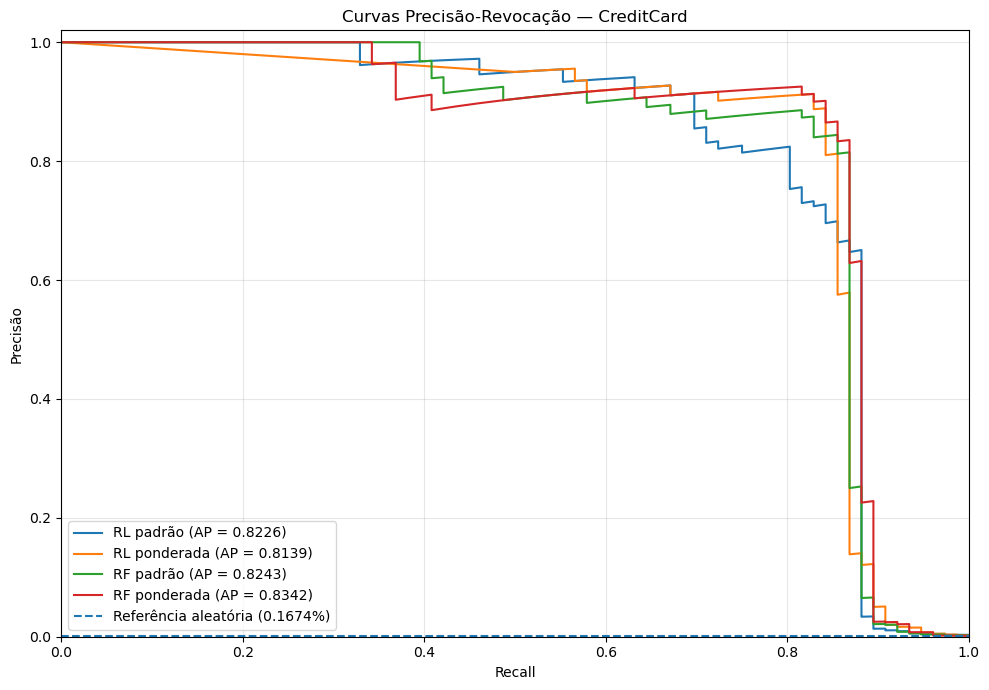

In [59]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

print("=== CURVAS PRECISÃO-REVOCAÇÃO — CREDITCARD ===")

plt.figure(figsize=(10, 7))

for nome, probabilidades in modelos_cc.items():

    precisao, recall, _ = precision_recall_curve(
        y_cc_validacao,
        probabilidades
    )

    ap = average_precision_score(
        y_cc_validacao,
        probabilidades
    )

    plt.plot(
        recall,
        precisao,
        label=f"{nome} (AP = {ap:.4f})"
    )

prevalencia = y_cc_validacao.mean()

plt.axhline(
    y=prevalencia,
    linestyle="--",
    label=f"Referência aleatória ({prevalencia:.4%})"
)

plt.title(
    "Curvas Precisão-Revocação — CreditCard"
)

plt.xlabel("Recall")
plt.ylabel("Precisão")

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
